In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import time
import jax.numpy as jnp
import equinox as eqx
import optax
import matplotlib.pyplot as plt

from pathlib import Path
from jax import random, vmap, config
from jax.lax import scan, dot_general, dynamic_slice_in_dim
from jax.tree_util import tree_map, tree_flatten
from jax.nn import gelu

config.update('jax_default_matmul_precision', 'float32')

%config InlineBackend.figure_format='retina'

In [2]:
def normalize_conv(A, s1=1.0, s2=1.0):
    # rescale the weights and the bias of a convolution (used to choose the initial scale)
    A = eqx.tree_at(lambda x: x.weight, A, A.weight * s1)
    try:
        A = eqx.tree_at(lambda x: x.bias, A, A.bias * s2)
    except:
        pass
    return A

class FFNO(eqx.Module):
    encoder: eqx.Module
    decoder: eqx.Module
    convs1: list
    convs2: list
    A: jnp.array

    def __init__(self, N_layers, N_features, N_modes, D, key, s1=1.0, s2=1.0, s3=1.0):
        n_in, n_processor, n_out = N_features

        keys = random.split(key, 3 + 2*N_layers)
        self.encoder = normalize_conv(eqx.nn.Conv(D, n_in, n_processor, 1, key=keys[-1]), s1=s1, s2=s2)
        self.decoder = normalize_conv(eqx.nn.Conv(D, n_processor, n_out, 1, key=keys[-2]), s1=s1, s2=s2)
        self.convs1 = [normalize_conv(eqx.nn.Conv(D, n_processor, n_processor, 1, key=key), s1=s1, s2=s2) for key in keys[:N_layers]]
        self.convs2 = [normalize_conv(eqx.nn.Conv(D, n_processor, n_processor, 1, key=key), s1=s1, s2=s2) for key in keys[N_layers:2*N_layers]]
        # complex spectral weights: [layer, c_in, c_out, mode, axis]
        self.A = random.normal(keys[-3], [N_layers, n_processor, n_processor, N_modes, D], dtype=jnp.complex64) * s3

    def __call__(self, u, x):
        u = jnp.concatenate([x, u], 0)  # the coordinates are the additional input channels
        u = self.encoder(u)
        for conv1, conv2, A in zip(self.convs1, self.convs2, self.A):
            u += gelu(conv2(gelu(conv1(self.spectral_conv(u, A)))))
        u = self.decoder(u)
        norm = jnp.linalg.norm(u.reshape(u.shape[0], -1), axis=1)
        u = u / norm.reshape([-1, ]+ [1,]*(u.ndim-1))
        return u

    def spectral_conv(self, v, A):
        # for each axis: FFT, keep the lowest modes, multiply by A (matrix product over channels in every mode), inverse FFT
        u = 0
        N = v.shape
        for i in range(A.shape[-1]):
            u_ = dynamic_slice_in_dim(jnp.fft.rfft(v, axis=i+1), 0, A.shape[-2], axis=i+1)
            u_ = dot_general(A[:, :, :, i], u_, (((1,), (0,)), ((2, ), (i+1, ))))
            u_ = jnp.moveaxis(u_, 0, i+1)
            u += jnp.fft.irfft(u_, axis=i+1, n=N[i+1])
        return u

# Deep POD: a network predicts the basis of a reduced model

For the problem $-(a u')'=f$ the network (a factorised FNO) takes the diffusion coefficient $a$ and the right-hand side $f$ and predicts $N_b$ basis functions $W$ on the grid. The basis $V$ is built from $W$ (optionally reweighted, see below) and orthonormalised with QR. The network is trained to minimise the $L_2$ projection error of the exact solution on $\mathrm{span}(V)$,
$$
\frac{\|u - V^T V u\|}{\|u\|}.
$$
At inference the reduced (Galerkin) model is assembled and solved, $u_r = V^T (VKV^T)^{-1} V M f$, and we report its relative error.

Two options are compared for the same network, initialisation and data:

- **without reweighting**: $V=\mathrm{QR}(W)$;
- **with reweighting**: $V=\mathrm{QR}(W L^{-1/2})$, where $L=\frac1h\,\mathrm{tridiag}(-1,2,-1)$ is the stiffness matrix for $a\equiv1$.

As a classical baseline we use POD: the basis is formed by the first $N_b$ left singular vectors of the matrix of the training solutions (the same basis for all samples), and the same Galerkin reduced model is built on it.

## Dataset ($N=512$)

The dataset with the stiffness and the mass matrices is generated in `01_elliptic_1d_fem.ipynb`.

In [3]:
import numpy as np

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir())
data_dir = root / "data"
data = jnp.load(data_dir / "diffusion_dataset_matrix.npz")
print({k: data[k].shape for k in data.keys()})

# network input: channels (a, f); target: the FEM solution
features = jnp.stack([data['diffusion coefficient'], data['righ-hand side']], axis=1)
targets = jnp.array(data['solution'])

targets_scale = jnp.max(jnp.abs(targets))
features = features / jnp.max(jnp.abs(features))
targets = targets / targets_scale

rhs = jnp.array(data['righ-hand side'])
diag = jnp.array(data['stiffness matrix diagonal'])
off_diag = jnp.array(data['stiffness matrix off-diagonal'])
M_mass = jnp.array(data['mass matrix'])
coordinates = jnp.array(data['grid points'])[None]  # (1, N): the coordinates as an input channel of the network
N_nodes = coordinates.shape[1]

def matrix_from_diagonals(diag, off):
    """Reconstruct the dense tridiagonal matrix from its diagonal and off-diagonal."""
    return jnp.diag(diag) + jnp.diag(off, 1) + jnp.diag(off, -1)

print(f"condition number of K (sample 0): {jnp.linalg.cond(matrix_from_diagonals(diag[0], off_diag[0])):.1e}")

{'diffusion coefficient': (1000, 512), 'righ-hand side': (1000, 512), 'solution': (1000, 512), 'grid points': (512,), 'stiffness matrix diagonal': (1000, 512), 'stiffness matrix off-diagonal': (1000, 511), 'mass matrix': (512, 512)}
condition number of K (sample 0): 2.4e+07


## Reweighting with $L^{-1/2}$

$K$ and $L$ are spectrally equivalent, so $\kappa(L^{-1/2}KL^{-1/2})\le a_{\max}/a_{\min}=810$ independently of $N$, while $\kappa(K)\sim10^7$ for $N=512$. Galerkin with the basis $V=WL^{-1/2}$ is the same as Galerkin with the preconditioned matrix $L^{-1/2}KL^{-1/2}$ and the basis $W$. The matrix $L^{-1/2}$ is symmetric and is computed once from the eigendecomposition of $L$ (the sine transform). Both options use the same code with a matrix $P$ that multiplies the network output from the right: $P=L^{-1/2}$ with reweighting and $P=I$ without.

In [4]:
h = 1 / (N_nodes + 1)
L = (2 * jnp.eye(N_nodes) - jnp.eye(N_nodes, k=1) - jnp.eye(N_nodes, k=-1)) / h
w_L, Q_L = jnp.linalg.eigh(L)
L_mhalf = (Q_L * w_L**-0.5) @ Q_L.T  # L^{-1/2}

options = {"without reweighting": jnp.eye(N_nodes), "with reweighting": L_mhalf}

### A note on numerical precision

The stiffness matrix is ill-conditioned ($\kappa(K)\sim10^7$ for $N=512$), so we first suspected that the reduced matrix $VKV^T$ could not be solved reliably in float32 and compared the float32 solution with one computed in float64. The float32 errors were indeed huge (a median relative error of about $0.9$ for a basis that is accurate in float64). The reason, however, was not the conditioning but the default precision of matrix multiplications on the A100 GPU: JAX uses TensorFloat-32 there, which keeps only about three significant digits. Setting `jax_default_matmul_precision` to `float32` in the first cell removes the problem, and with it the float32 and the float64 solutions agree to about $1\%$. All results below are therefore computed in plain float32.

In [5]:
def get_basis(model, input, x, P):
    # orthonormal basis (N_basis, N): QR of the whole output of the network, multiplied by P from the right
    return jnp.linalg.qr((model(input, x) @ P).T)[0].T

def projection_loss(model, input, target, x, P):
    basis = get_basis(model, input, x, P)
    return jnp.linalg.norm(target - basis.T @ (basis @ target)) / jnp.linalg.norm(target)

def batch_projection_loss(model, input, target, x, P):
    return jnp.mean(vmap(projection_loss, in_axes=(None, 0, 0, None, None))(model, input, target, x, P))

compute_loss_and_grads = eqx.filter_value_and_grad(batch_projection_loss)

def make_step_scan(carry, n, optim):
    model, features, targets, x, P, opt_state = carry
    loss, grads = compute_loss_and_grads(model, features[n], targets[n], x, P)
    grads = tree_map(lambda x: x.conj(), grads)  # the spectral weights are complex
    updates, opt_state = optim.update(grads, opt_state, eqx.filter(model, eqx.is_array))
    model = eqx.apply_updates(model, updates)
    return [model, features, targets, x, P, opt_state], loss

# Galerkin reduced model. `B` has shape (N_samples, N_basis, N): a (not yet orthonormal) basis for every sample.
def network_bases(model, P):
    return vmap(lambda f: model(f, coordinates) @ P)(features)

def predict(B):
    # Galerkin solution of the reduced model for all samples
    def step(carry, i):
        V = jnp.linalg.qr(B[i].T)[0].T
        A = V @ matrix_from_diagonals(diag[i], off_diag[i]) @ V.T
        return carry, V.T @ jnp.linalg.solve(A, V @ M_mass @ rhs[i]) / targets_scale
    return scan(step, 0, jnp.arange(B.shape[0]))[1]

def rel_errors(pred):
    pred, t = np.array(pred, dtype=np.float64), np.array(targets, dtype=np.float64)
    return np.linalg.norm(pred - t, axis=1) / np.linalg.norm(t, axis=1)

In [6]:
N_processor = 64  # number of channels in the Fourier layers
N_layers = 4
N_modes = 16  # number of retained Fourier modes
N_epoch = 1000
N_train = 900
N_batch = 10
learning_rate = 1e-4
D = features.ndim - 2  # dimension of the domain
N_run = N_epoch * N_train // N_batch  # total number of updates
basis_sizes = [5, 10, 15, 20]

results = {}
for N_basis in basis_sizes:
    for name, P in options.items():
        keys = random.split(random.PRNGKey(344))  # the same initialisation and batches for both options
        N_features = [coordinates.shape[0] + features.shape[1], N_processor, N_basis]
        model = FFNO(N_layers, N_features, N_modes, D, keys[0], s1=1e-1, s2=0, s3=1e-1)
        optim = optax.lion(learning_rate=learning_rate)
        opt_state = optim.init(eqx.filter(model, eqx.is_array))
        n = random.choice(keys[1], N_train, shape=(N_run, N_batch))
        carry = [model, features, targets, coordinates, P, opt_state]

        start = time.time()
        carry, history = scan(lambda c, i: make_step_scan(c, i, optim), carry, n)
        history.block_until_ready()
        training_time = time.time() - start
        model = carry[0]

        results[(N_basis, name)] = {"history": history, "time": training_time, "model": model,
                                    "errors": rel_errors(predict(network_bases(model, P)))}
        print(f"N_basis = {N_basis:<3} {name:<20} training time {training_time:5.1f} s, final training loss {history[-1000:].mean():.2e}")

N_basis = 5   without reweighting  training time 201.4 s, final training loss 3.37e-03
N_basis = 5   with reweighting     training time 201.3 s, final training loss 4.36e-03
N_basis = 10  without reweighting  training time 220.1 s, final training loss 1.58e-03
N_basis = 10  with reweighting     training time 220.0 s, final training loss 1.59e-03
N_basis = 15  without reweighting  training time 248.5 s, final training loss 8.89e-04
N_basis = 15  with reweighting     training time 246.3 s, final training loss 6.05e-04
N_basis = 20  without reweighting  training time 269.4 s, final training loss 4.28e-04
N_basis = 20  with reweighting     training time 269.9 s, final training loss 3.39e-04


## Classical POD

The basis is the set of the first $N_b$ left singular vectors of the matrix of the training solutions (the same basis for all samples). Only the 900 training solutions are used; the 100 test samples are not seen.

In [7]:
pod_sizes = [5, 10, 15, 20, 25, 30]
_, S_pod, Vt_pod = np.linalg.svd(np.array(targets[:N_train], dtype=np.float64), full_matrices=False)
for N_basis in pod_sizes:
    B = jnp.broadcast_to(jnp.array(Vt_pod[:N_basis], dtype=jnp.float32), (features.shape[0], N_basis, N_nodes))
    results[(N_basis, "POD")] = {"errors": rel_errors(predict(B))}

## Results

Relative error of the Galerkin solution of the reduced model on the 900 training and 100 test samples.

In [8]:
print(f"{'N_basis':<8}{'method':<22}{'train mean':>11}{'train med':>11}{'test mean':>11}{'test med':>11}{'test max':>10}")
for (N_basis, name), r in sorted(results.items(), key=lambda kv: (kv[0][0], kv[0][1] != "POD", kv[0][1])):
    e = r["errors"]
    print(f"{N_basis:<8}{name:<22}{np.mean(e[:N_train]):11.4f}{np.median(e[:N_train]):11.4f}{np.mean(e[N_train:]):11.4f}{np.median(e[N_train:]):11.4f}{np.max(e[N_train:]):10.3f}")

N_basis method                 train mean  train med  test mean   test med  test max
5       POD                        0.9347     0.9806     0.9120     0.9771     1.204
5       with reweighting           0.4003     0.4009     0.5935     0.6364     0.968
5       without reweighting        0.2548     0.2335     0.5351     0.5574     0.976
10      POD                        0.7439     0.7957     0.7253     0.7677     0.984
10      with reweighting           0.1428     0.1227     0.3018     0.2607     0.782
10      without reweighting        0.1179     0.1045     0.2531     0.2136     0.668
15      POD                        0.5861     0.5893     0.5760     0.5793     0.962
15      with reweighting           0.0313     0.0243     0.1123     0.0753     0.501
15      without reweighting        0.0447     0.0365     0.1372     0.0986     0.807
20      POD                        0.4887     0.4781     0.4804     0.4784     0.926
20      with reweighting           0.0183     0.0135     0.0557  

## Visualisation

- the **training curves**: for every number of basis functions the loss on the minibatches (light grey) and its average over an epoch (black), without (left) and with (right) the reweighting;
- the **error against the number of basis functions** for POD and for the learned bases, with and without the reweighting (mean and median over the test samples).

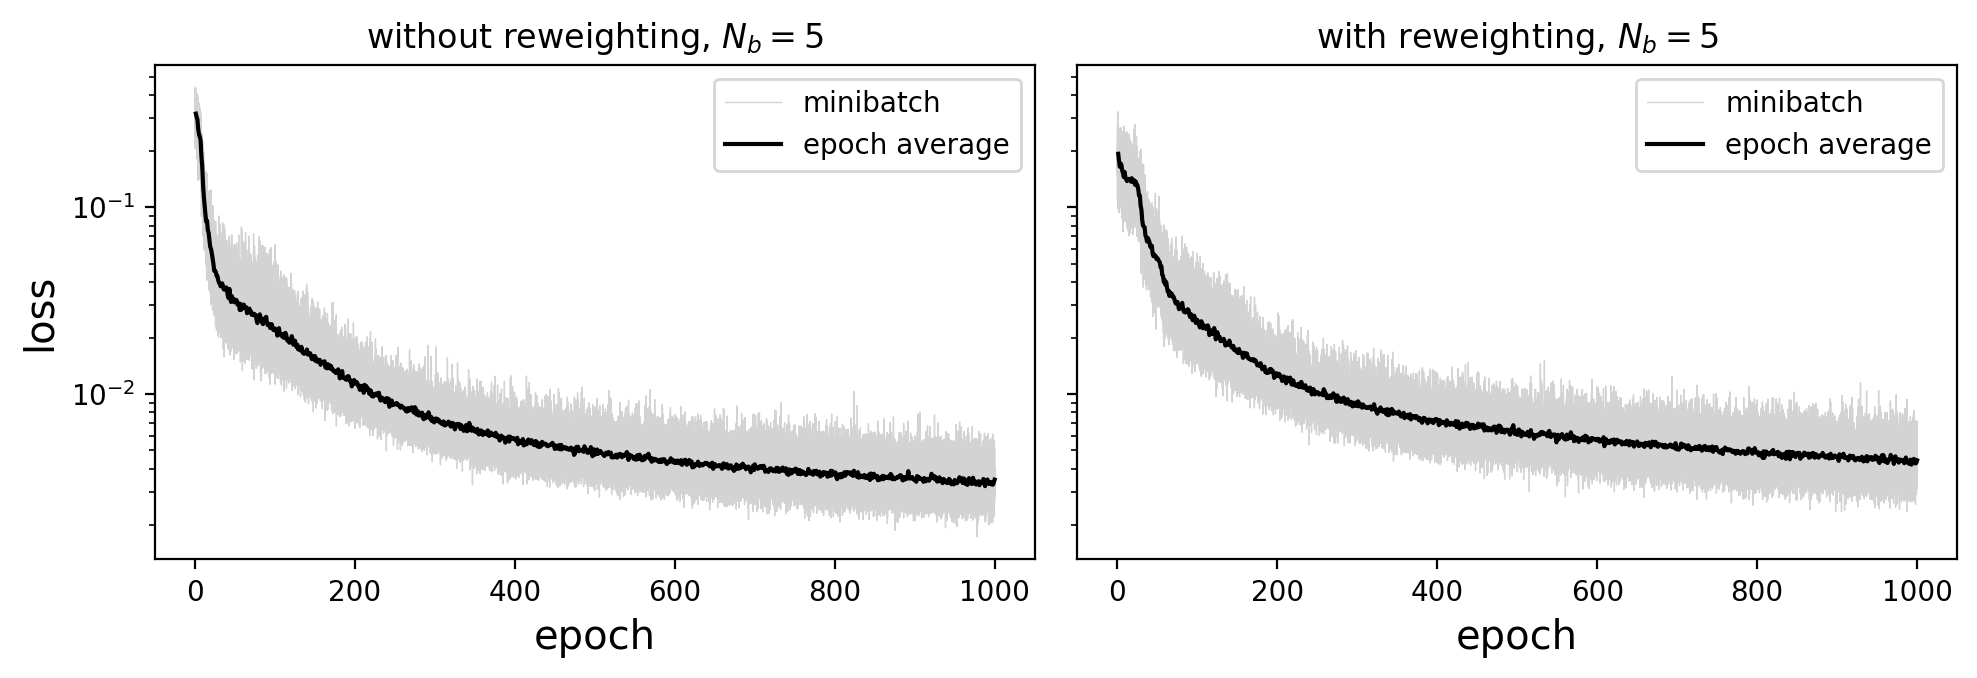

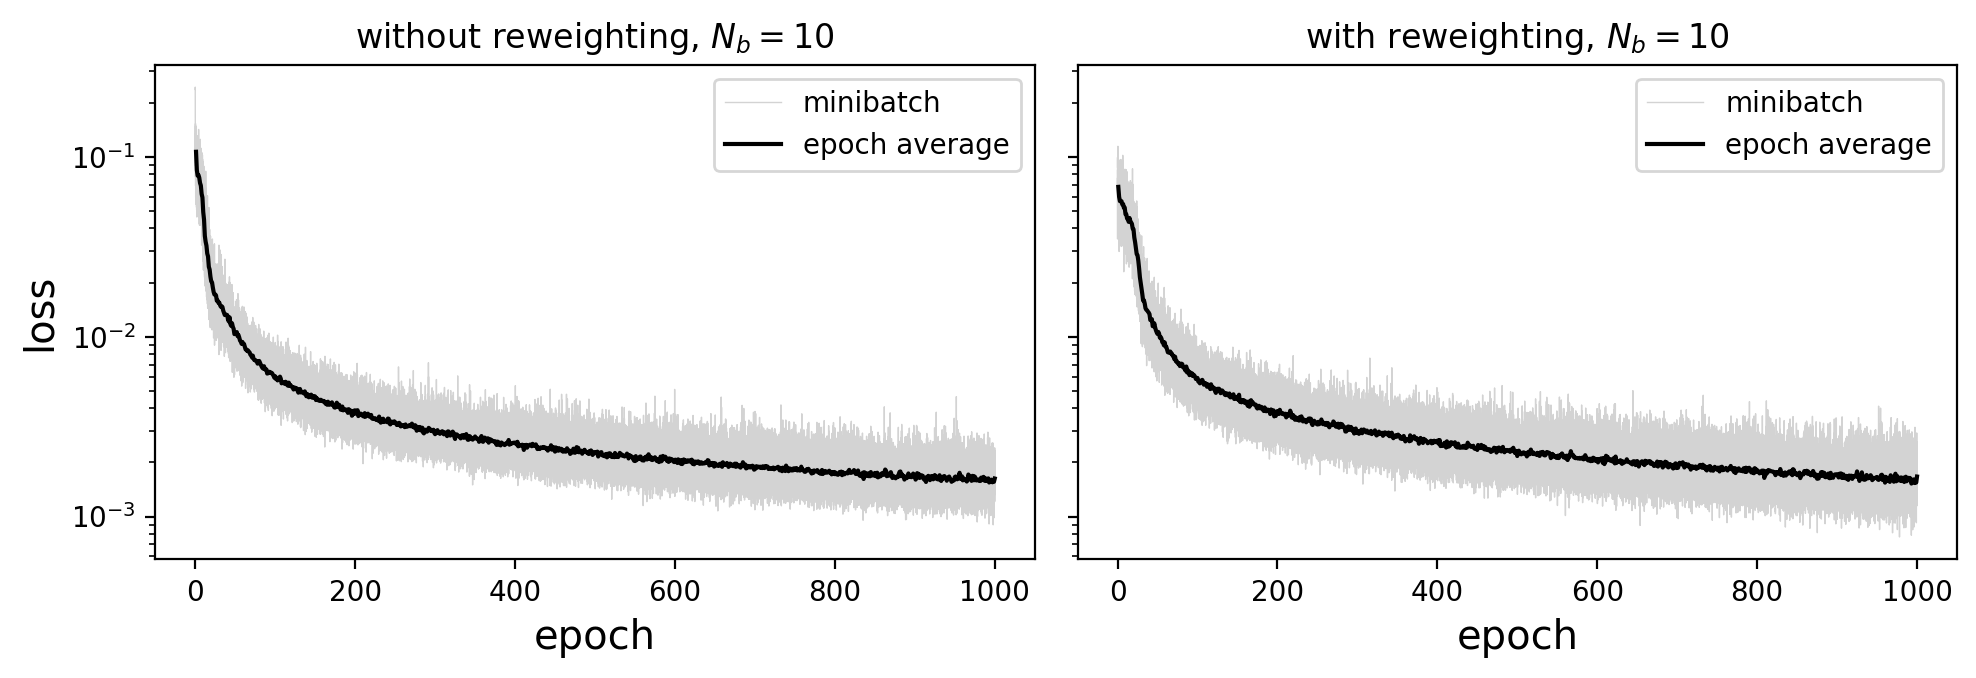

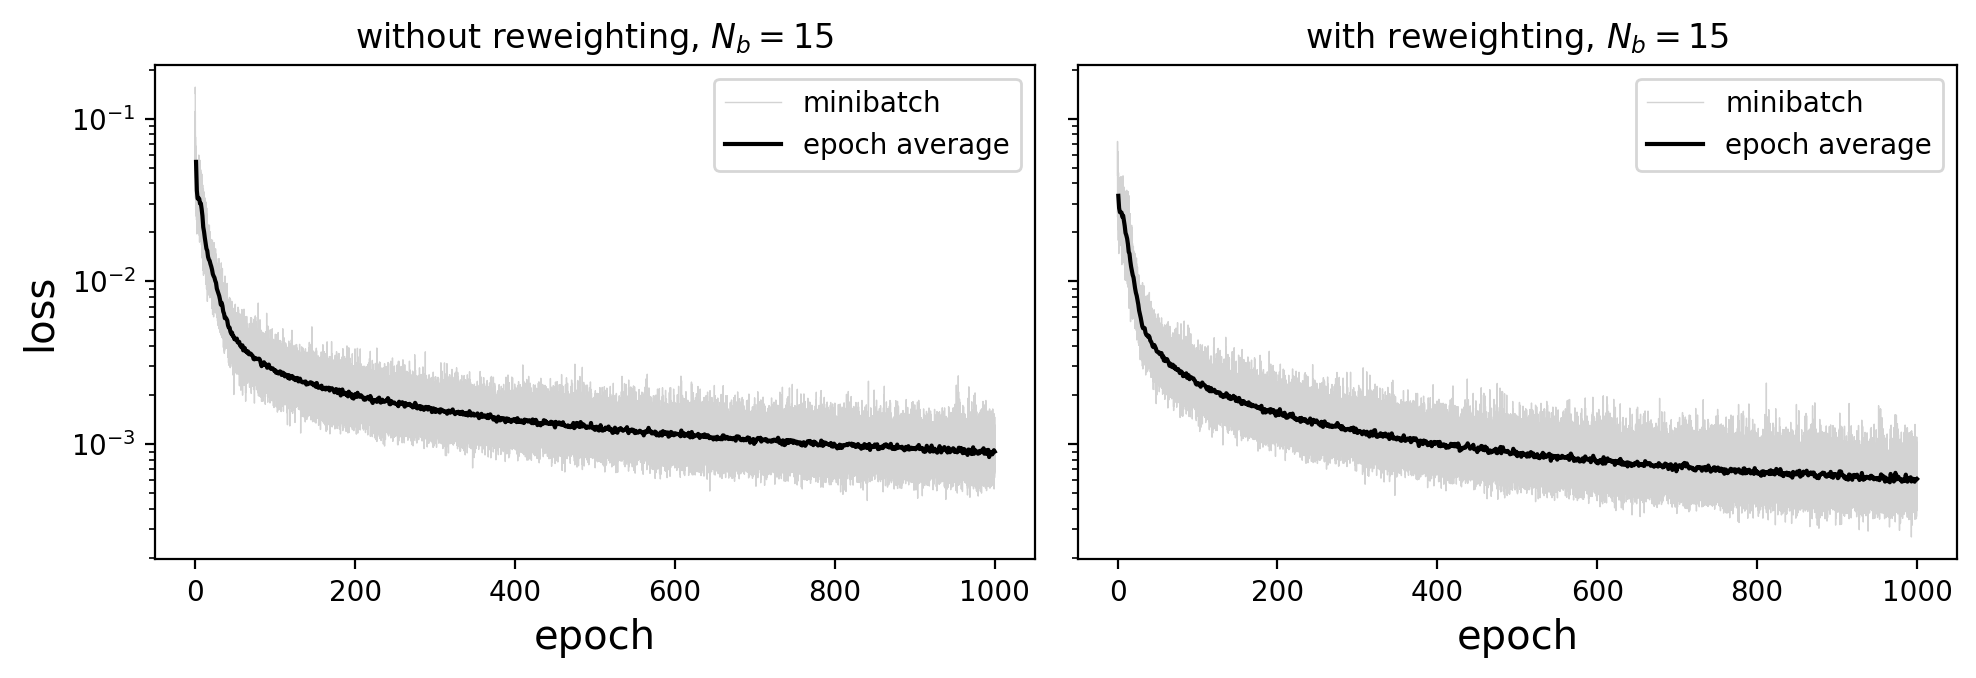

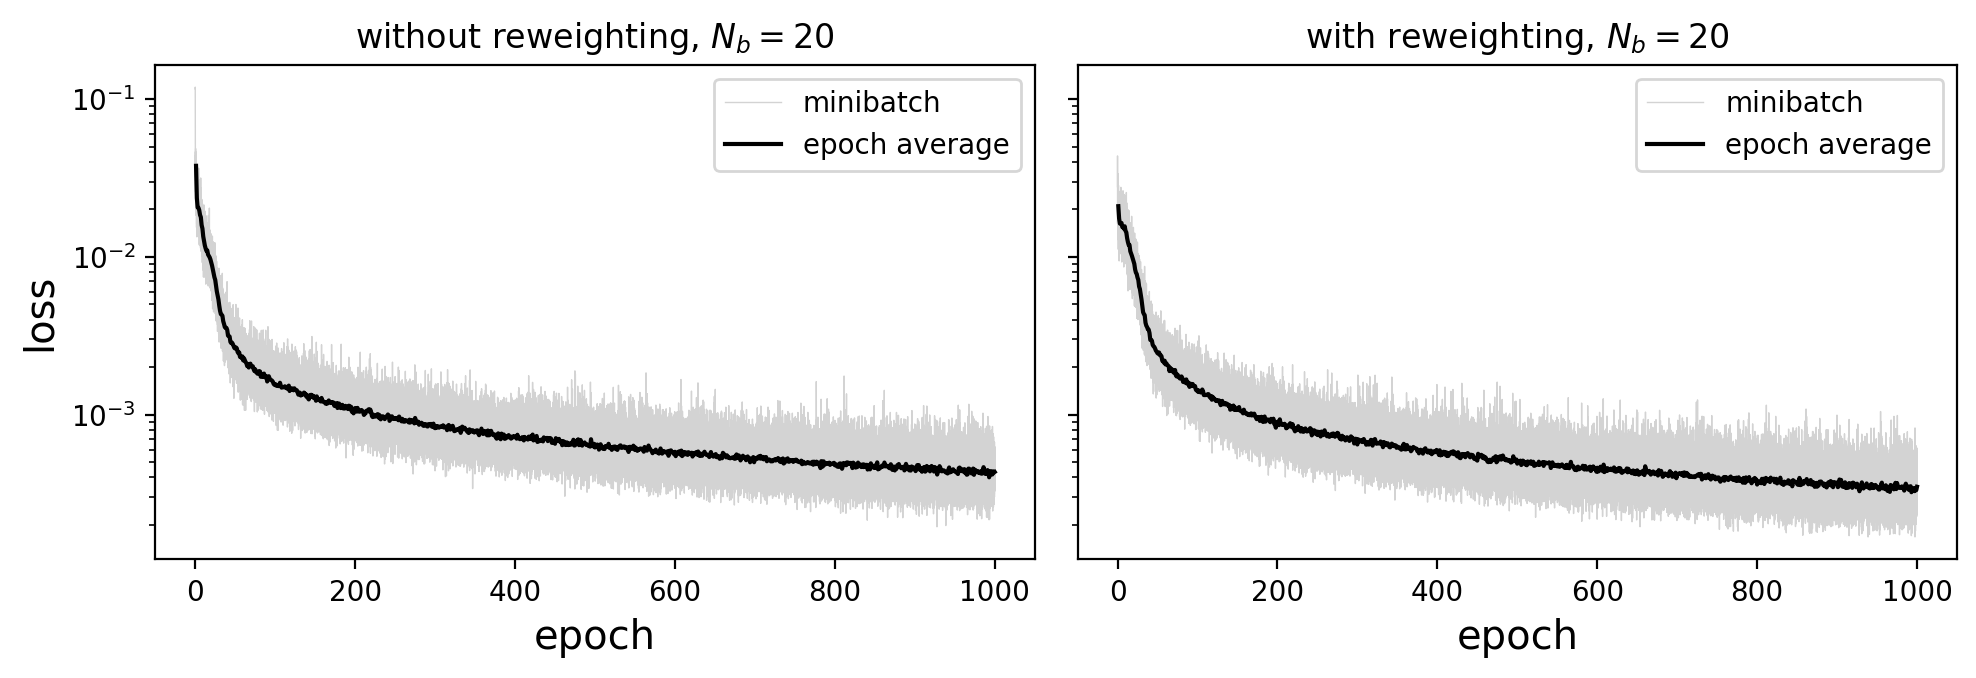

In [9]:
def plot_convergence(N_basis, figure_name=None):
    epochs = jnp.arange(1, N_epoch + 1)
    steps_per_epoch = N_train // N_batch
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
    for ax, name in zip(axes, options):
        history = results[(N_basis, name)]["history"]
        ax.plot(epochs[0] - 1 + jnp.arange(N_run) / steps_per_epoch, history, color="lightgray", linewidth=0.5, label="minibatch")
        ax.plot(epochs, history.reshape(N_epoch, steps_per_epoch).mean(axis=1), color="black", label="epoch average")
        ax.set_yscale("log")
        ax.set_xlabel("epoch", fontsize="x-large")
        ax.set_title(f"{name}, $N_b={N_basis}$")
        ax.legend()
    axes[0].set_ylabel("loss", fontsize="x-large")
    plt.tight_layout()

    if figure_name is not None:
        plt.savefig(data_dir / f"{figure_name}_convergence.pdf", format='pdf', bbox_inches='tight')

for N_basis in basis_sizes:
    plot_convergence(N_basis, figure_name=f"DeepPOD_{N_basis}")

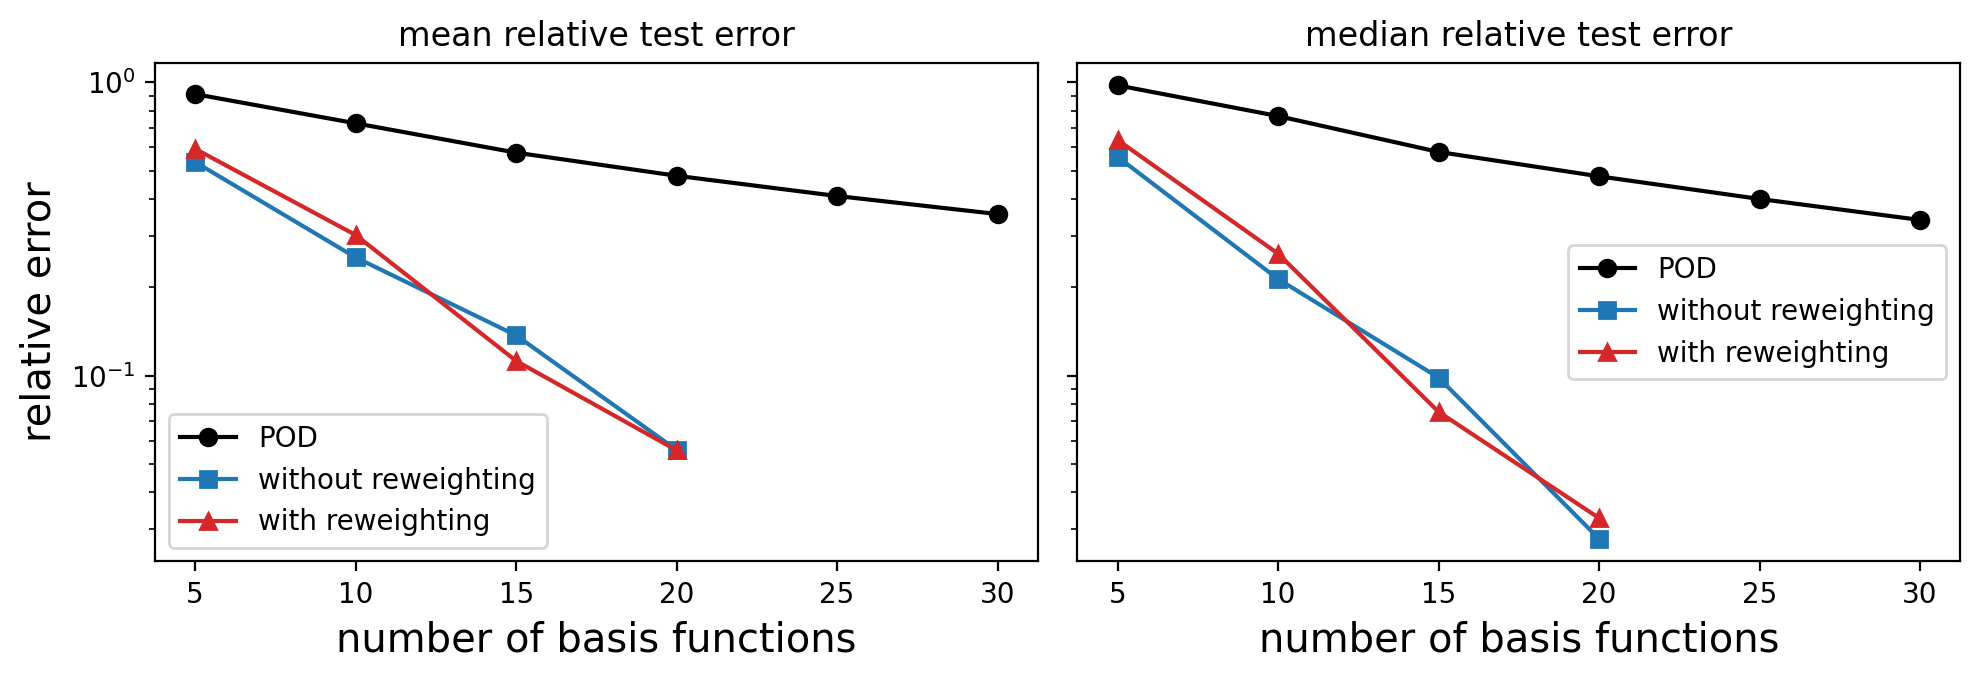

In [10]:
def plot_errors(figure_name=None):
    styles = {"POD": ("black", "o", pod_sizes), "without reweighting": ("tab:blue", "s", basis_sizes), "with reweighting": ("tab:red", "^", basis_sizes)}
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
    for ax, (stat_name, stat) in zip(axes, [("mean", np.mean), ("median", np.median)]):
        for name, (color, marker, sizes) in styles.items():
            ax.plot(sizes, [stat(results[(k, name)]["errors"][N_train:]) for k in sizes], color=color, marker=marker, label=name)
        ax.set_yscale("log")
        ax.set_xlabel("number of basis functions", fontsize="x-large")
        ax.set_title(f"{stat_name} relative test error")
        ax.legend()
    axes[0].set_ylabel("relative error", fontsize="x-large")
    plt.tight_layout()

    if figure_name is not None:
        plt.savefig(data_dir / f"{figure_name}_errors.pdf", format='pdf', bbox_inches='tight')

plot_errors(figure_name="DeepPOD")